## This notebook contains scripts for creating additional MHW/MCS analysis products.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns
import seaborn.objects as so
from seaborn import axes_style
import matplotlib.dates as mdates
from datetime import timedelta


# Script 1 (a,b)

Creates a stacked bar chart of MHW/MCS events. It shows the number of MHW/MCS days by season for each year.

### Script 1a

In the first step (Script 1a), the file XXX is generated from MHW_cat1_sumF.csv. It contains a table of the total number of MHW/MCS days by season for each year.

In [3]:
# Script 1a

# =========================================================
# Input and output files
# =========================================================

INPUT_FILE = r"D:\XRAST\HMWBP\BPMHW\BP_reg_mhw_sumF.csv"
OUTPUT_FILE = r"D:\XRAST\HMWBP\BPMHW\BP_reg_mhw_sumF_seasons.csv"


# =========================================================
# Read the data
# =========================================================

df = pd.read_csv(INPUT_FILE)

# Convert dates to datetime
df["date_start"] = pd.to_datetime(df["date_start"])
df["date_end"] = pd.to_datetime(df["date_end"])


# =========================================================
# Calculate the number of days in each season
# =========================================================

data = {}

for _, row in df.iterrows():

    current = row["date_start"]
    end = row["date_end"]
    area = row["area_km2"]

    # Process every individual day of the MHW event
    while current <= end:

        d = current.date()
        y = current.year
        m = current.month

        # Create a new record for the calendar year if necessary
        if y not in data:
            data[y] = {
                "all_days": set(),
                "winter": set(),
                "spring": set(),
                "summer": set(),
                "fall": set(),
                "max_km2": 0.0
            }

        # Add the day to the total number of event days
        data[y]["all_days"].add(d)

        # Store the maximum area occurring during the year
        data[y]["max_km2"] = max(data[y]["max_km2"], area)

        # Assign the individual day to its actual season
        if m in (1, 2, 3):
            data[y]["winter"].add(d)

        elif m in (4, 5, 6):
            data[y]["spring"].add(d)

        elif m in (7, 8, 9):
            data[y]["summer"].add(d)

        else:
            data[y]["fall"].add(d)

        # Move to the next day
        current += timedelta(days=1)


# =========================================================
# Create the results table
# =========================================================

rows = []

for y in sorted(data):

    v = data[y]

    rows.append({
        "year": y,
        "days_sum": len(v["all_days"]),
        "max_km2": v["max_km2"],
        "days_sum_winter": len(v["winter"]),
        "days_sum_spring": len(v["spring"]),
        "days_sum_summer": len(v["summer"]),
        "days_sum_fall": len(v["fall"])
    })


result = pd.DataFrame(rows)


# =========================================================
# Save the results
# =========================================================

result.to_csv(OUTPUT_FILE, index=False)

print(result)

    year  days_sum       max_km2  days_sum_winter  days_sum_spring  \
0   1993       101  30148.320560               30               57   
1   1994        47   8570.876831                0               10   
2   1995        41   8378.162756                0                0   
3   1996        16   3766.090315                0                0   
4   1997        81  22064.128428                0                1   
5   1998        58  15488.985493               25               33   
6   1999        72  23739.760979                0               15   
7   2000       151  41453.124186                0               68   
8   2001        88  41453.124186               58                0   
9   2002       150  32415.160698                0               60   
10  2003        24    842.715786                0                0   
11  2004        44   4203.779909                0               16   
12  2005       109  35750.094099               17               17   
13  2006       156  

### Script 1b

In the second step (Script 1b), the figure is generated from file XXX.


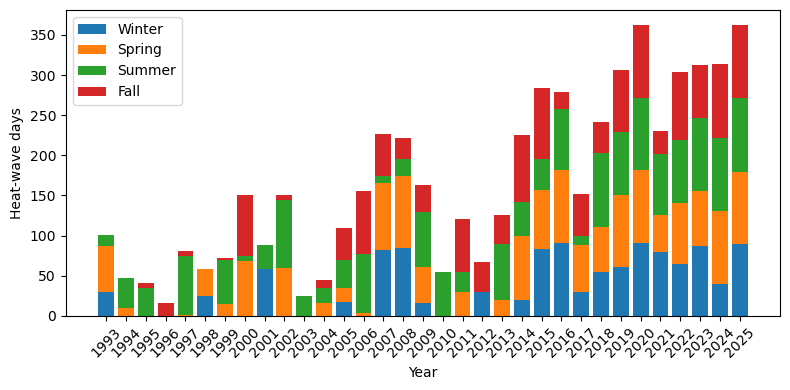

In [4]:

# Read data
df = pd.read_csv(r"D:\XRAST\HMWBP\BPMHW\BP_reg_mhw_sumF_seasons.csv") 

# Create the plot
plt.figure(figsize=(8, 4))

plt.bar(df['year'], df['days_sum_winter'], label='Winter')
plt.bar(df['year'], df['days_sum_spring'],
        bottom=df['days_sum_winter'], label='Spring')
plt.bar(df['year'], df['days_sum_summer'],
        bottom=df['days_sum_winter'] + df['days_sum_spring'],
        label='Summer')
plt.bar(df['year'], df['days_sum_fall'],
        bottom=df['days_sum_winter'] + df['days_sum_spring'] + df['days_sum_summer'],
        label='Fall')

# Axis labels and legend
plt.xlabel('Year')
plt.ylabel('Heat-wave days')
#plt.title('Number of days by season')
plt.legend()

plt.xticks(df['year'], rotation=45)
plt.tight_layout()
plt.savefig(r'D:/XRAST/HMWBP/BPMHW/BPFIGMHW/BP_mhw_seasons.jpg', dpi=300, bbox_inches="tight")
plt.show()

# Script 2 

Spatial extent (surface area) of MHWs in different categories, based on summary statistics

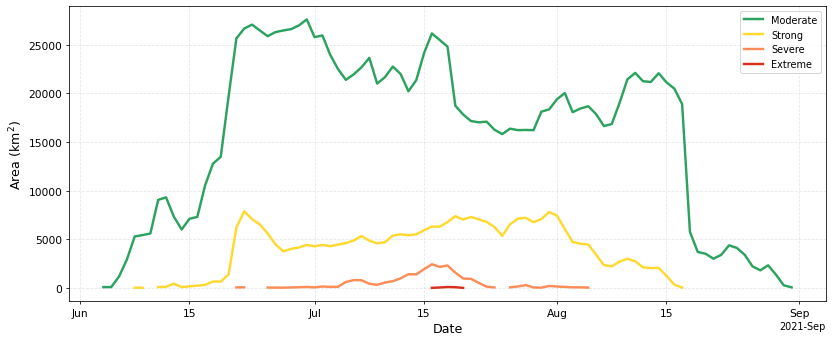

In [2]:

# -------------------------------------------------------
# Input files

# -------------------------------------------------------

sssts1 = r'D:/XRAST/HMWBP/BPMHW/BPFIGMHW/ID9151_km2_cat1.csv'
sssts2 = r'D:/XRAST/HMWBP/BPMHW/BPFIGMHW/ID9151_km2_cat2.csv'
sssts3 = r'D:/XRAST/HMWBP/BPMHW/BPFIGMHW/ID9151_km2_cat3.csv'
sssts4 = r'D:/XRAST/HMWBP/BPMHW/BPFIGMHW/ID9151_km2_cat4.csv'

files = [sssts1, sssts2, sssts3, sssts4]

# -------------------------------------------------------
# Event categories
# -------------------------------------------------------

classes = ['Moderate', 'Strong', 'Severe', 'Extreme']

# One color per class
class_colors = {
    'Moderate': '#2ca25f',
    'Strong':   '#ffd92f',
    'Severe':   '#fc8d59',
    'Extreme':  '#d7301f'
}

# -------------------------------------------------------
# Figure
# -------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5), dpi=70)

already_added = set()

# -------------------------------------------------------
# Read and plot files
# -------------------------------------------------------

for file, cls in zip(files, classes):

    # Read CSV
    # skipinitialspace=True removes spaces after commas
    df = pd.read_csv(file, skipinitialspace=True)

    # Convert time
    df['time'] = pd.to_datetime(df['time'])

    # Convert sum to numeric
    df['sum'] = pd.to_numeric(df['sum'], errors='coerce')

    # Remove rows where time or sum is missing
    df = df.dropna(subset=['time', 'sum'])

     # Zero area = no MHW → do not draw
    df.loc[df['sum'] == 0, 'sum'] = float('nan')

    # Add legend label only once
    label = cls if cls not in already_added else None
    already_added.add(cls)

    # Plot area
    ax.plot(
        df['time'],
        df['sum'],
        lw=2.5,
        color=class_colors[cls],
        label=label
    )

# -------------------------------------------------------
# Date axis
# -------------------------------------------------------

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)

ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

# -------------------------------------------------------
# Labels
# -------------------------------------------------------

ax.set_xlabel('Date', fontsize=13)
ax.set_ylabel(r'Area (km$^2$)', fontsize=13)

# -------------------------------------------------------
# Legend
# -------------------------------------------------------

# ax.legend(
#     frameon=,
#     fontsize=11,
#     ncol=4
# )

ax.legend(
    loc="best",
    frameon=True
)

# -------------------------------------------------------
# Grid and ticks
# -------------------------------------------------------

ax.grid(
    True,
    linestyle='--',
    alpha=0.3
)

ax.tick_params(
    axis='both',
    labelsize=11
)

plt.tight_layout()

#-------------------------------------------------------
#Save
#-------------------------------------------------------

plt.savefig(
    r'D:/XRAST/HMWBP/BPMHW/BPFIGMHW/ID9151_km2_c1234.jpg',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Script 3 

Calculates basic statistics describing MHW/MCS events over the entire period, using the temperature anomaly variable from the file generated by the Summary Statistics function:
minimum intensity
maximum intensity
cumulative intensity


In [2]:
# data from Xraster

stats=r'D:/XRAST/wersja5/MSHW/ID_1_inobj47244_stat.csv'

TimeS=pd.read_csv(stats)
TimeS['time'] = pd.to_datetime(TimeS['time'])

print(TimeS["mean"].mean()  )
print(TimeS["max"].max()  )
print(TimeS["mean"].sum()  )

2.1677666666666666
6.6433
65.033


# Script 4

Creates a figure showing the time series of four variables for a given object: climatological mean, minimum temperature, mean temperature, and maximum temperature.

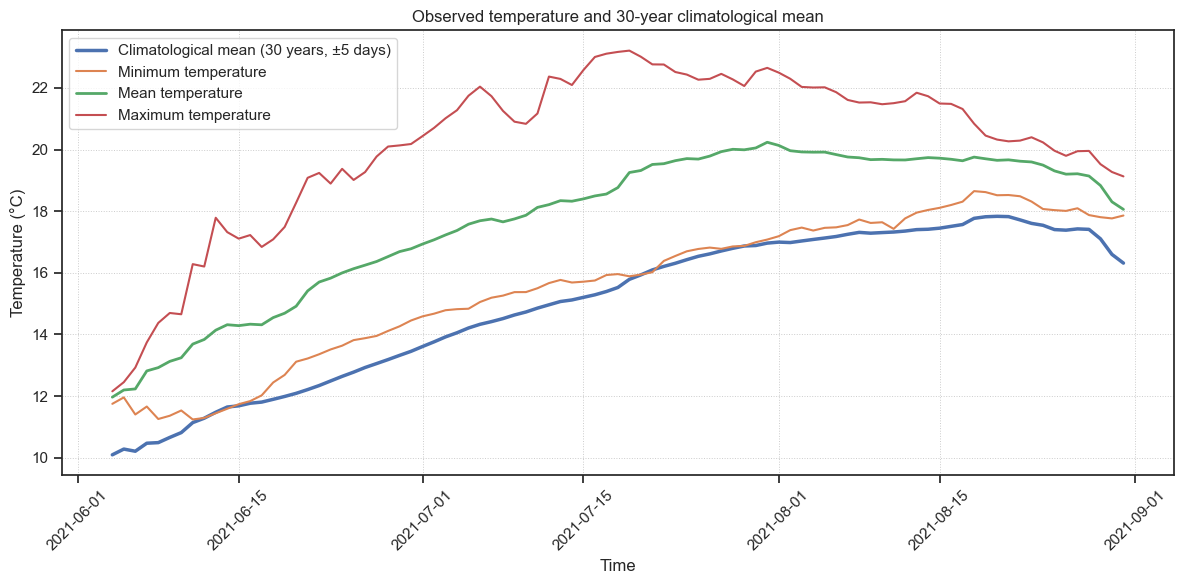

In [3]:



# ============================================================
# FILES
# ============================================================

file_climatology = r"D:/XRAST/HMWBP/BPMHW/ID_91511_mean_clim.csv"
file_temperature = r"D:/XRAST/HMWBP/BPMHW/ID_91511_temp_stat.csv"


# ============================================================
# READ DATA
# ============================================================

df_clim = pd.read_csv(
    file_climatology,
    skipinitialspace=True
)

df_temp = pd.read_csv(
    file_temperature,
    skipinitialspace=True
)


# ============================================================
# TIME
# ============================================================

df_clim["time"] = pd.to_datetime(df_clim["time"])
df_temp["time"] = pd.to_datetime(df_temp["time"])


# ============================================================
# SORT
# ============================================================

df_clim = df_clim.sort_values("time")
df_temp = df_temp.sort_values("time")


# ============================================================
# PLOT
# ============================================================

sns.set_theme(
    style="ticks",
    context="notebook"
)

fig, ax = plt.subplots(
    figsize=(12, 6)
)


# ------------------------------------------------------------
# 30-year climatological mean
# ±5-day window
# ------------------------------------------------------------

ax.plot(
    df_clim["time"],
    df_clim["mean"],
    linewidth=2.5,
    label="Climatological mean (30 years, ±5 days)"
)


# ------------------------------------------------------------
# Minimum temperature
# ------------------------------------------------------------

ax.plot(
    df_temp["time"],
    df_temp["min"],
    linewidth=1.5,
    label="Minimum temperature"
)


# ------------------------------------------------------------
# Mean temperature
# ------------------------------------------------------------

ax.plot(
    df_temp["time"],
    df_temp["mean"],
    linewidth=2.0,
    label="Mean temperature"
)


# ------------------------------------------------------------
# Maximum temperature
# ------------------------------------------------------------

ax.plot(
    df_temp["time"],
    df_temp["max"],
    linewidth=1.5,
    label="Maximum temperature"
)


# ============================================================
# AXES
# ============================================================

ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")

ax.set_title(
    "Observed temperature and 30-year climatological mean"
)


# ============================================================
# DATE FORMAT
# ============================================================

ax.xaxis.set_major_locator(
    mdates.AutoDateLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m-%d")
)

plt.xticks(rotation=45)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="best",
    frameon=True
)


# ============================================================
# GRID
# ============================================================

ax.grid(
    True,
    linestyle=":",
    linewidth=0.7
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()



#-------------------------------------------------------
#Save
#-------------------------------------------------------

plt.savefig(
    r"D:/XRAST/HMWBP/BPMHW/BPFIGMHW/ID91511__temp_climatmean.jpg",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Script 5
Creates a figure showing the annual mean maximum intensity of MHWs/MCSs...

year
1993    2.649867
1994    3.064706
1995    3.063032
1996    2.408338
1997    3.305180
1998    2.067921
1999    2.838210
2000    2.705980
2001    1.946925
2002    3.112490
2003    2.085229
2004    2.473657
2005    2.355990
2006    3.183574
2007    2.509219
2008    2.285555
2009    2.200879
2010    3.127625
2011    2.324765
2012    1.851901
2013    2.289325
2014    2.465366
2015    2.038782
2016    2.686534
2017    2.245231
2018    3.470108
2019    2.660447
2020    2.941127
2021    3.113498
2022    2.736636
2023    2.955179
2024    3.116847
2025    2.785768
Name: max, dtype: float64


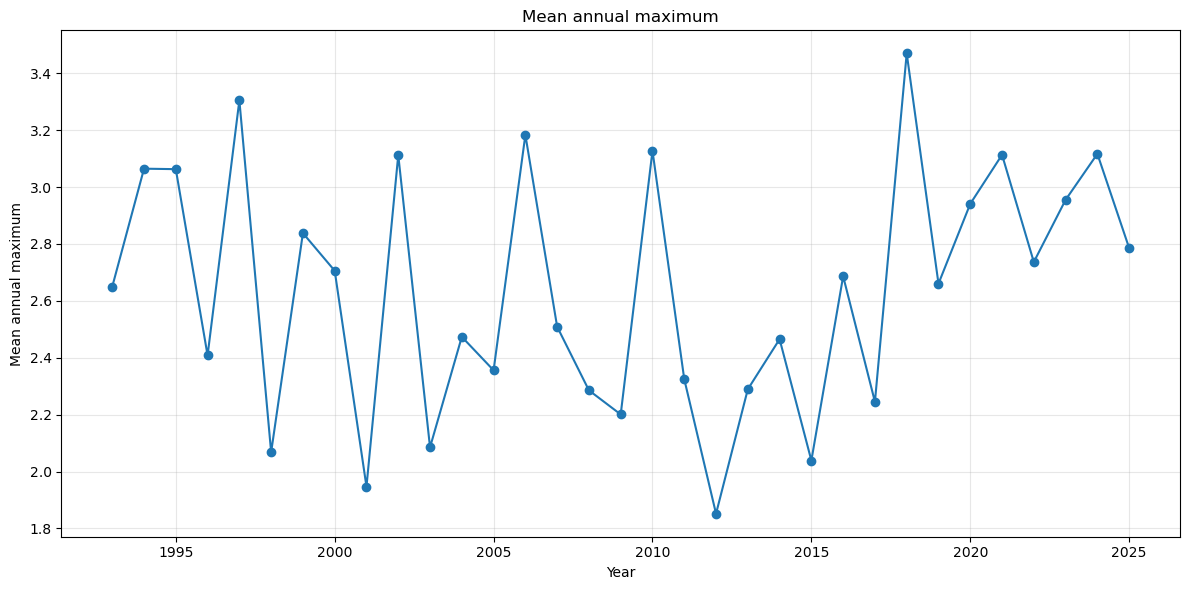

In [3]:

# ---------------------------------------------------------
# 1. Read the TXT file
# ---------------------------------------------------------

file = r"D:/XRAST/HMWBP/BPMHW/BP_mhw_max_intens_stat.csv"

df = pd.read_csv(file, skipinitialspace=True)

# Convert the time column to datetime
df["time"] = pd.to_datetime(df["time"])

# ---------------------------------------------------------
# 2. Calculate the mean of MAX values for each year
# ---------------------------------------------------------

# Extract the year from the time column
df["year"] = df["time"].dt.year

# Calculate the mean of daily MAX values for each year
yearly_max = df.groupby("year")["max"].mean()

print(yearly_max)


# ---------------------------------------------------------
# 3. Plot the results
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    yearly_max.index,
    yearly_max.values,
    marker="o",
    linewidth=1.5
)

ax.set_xlabel("Year")
ax.set_ylabel("Mean annual maximum")
ax.set_title("Mean annual maximum")

ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    r"D:/XRAST/HMWBP/BPMHW/BPFIGMHW/BP_mhw_mean_an_maximum.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Script 6

Adds a column containing the category of each object to the text file ...\_sumF.csv.


In [8]:
# ============================================================
# INPUT FILES
# ============================================================

# MHW objects
objects_file = r"D:\XRAST\HMWBP\BPMHW\BP_reg_mhw_sumF.csv"

# Daily statistics
statistics_file = r"D:\XRAST\HMWBP\BPMHW\BP_mhw_categ_stat.csv"

# Output file
output_file = r"D:\XRAST\HMWBP\BPMHW\BP_reg_mhw_sumF2.csv"


# ============================================================
# READ MHW OBJECTS
# ============================================================

objects = pd.read_csv(objects_file)

# Convert dates to datetime
objects["date_start"] = pd.to_datetime(objects["date_start"])
objects["date_end"] = pd.to_datetime(objects["date_end"])
objects["date_of_max"] = pd.to_datetime(objects["date_of_max"])


# ============================================================
# READ DAILY STATISTICS
# ============================================================

stats = pd.read_csv(
    statistics_file,
    skipinitialspace=True
)

# Convert time to datetime
stats["time"] = pd.to_datetime(stats["time"])

# Make sure max is numeric
stats["max"] = pd.to_numeric(stats["max"], errors="coerce")


# ============================================================
# CREATE DATE -> MAX CATEGORY LOOKUP
# ============================================================

daily_max = stats.set_index("time")["max"]


# ============================================================
# FUNCTION TO DETERMINE max_cat FOR EACH OBJECT
# ============================================================

def get_max_cat(row):

    start = row["date_start"]
    end = row["date_end"]

    # Select daily max values during the lifetime of the object
    values = daily_max.loc[start:end]

    # Remove NaN
    values = values.dropna()

    if len(values) == 0:
        return np.nan

    # Maximum category reached by the object
    return int(values.max())


# ============================================================
# CALCULATE max_cat
# ============================================================

objects["max_cat"] = objects.apply(get_max_cat, axis=1)


# ============================================================
# SAVE RESULT
# ============================================================

objects.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d"
)


# ============================================================
# DISPLAY RESULT
# ============================================================

print(objects.head(20))

print("\nNumber of objects:", len(objects))
print("\nmax_cat distribution:")
print(objects["max_cat"].value_counts().sort_index())

print("\nOutput file:")
print(output_file)

        id  max_number_of_cells date_start   date_end date_of_max  days  \
0    79646                13456 2019-10-16 2020-06-24  2020-02-03   253   
1    86326                13456 2020-09-21 2021-03-21  2020-11-19   182   
2   114762                13442 2024-12-22 2025-05-15  2025-04-04   145   
3    22997                13355 2006-09-18 2006-11-04  2006-10-26    48   
4   106035                13354 2023-08-14 2023-11-28  2023-09-30   107   
5    98360                13235 2022-10-07 2022-12-18  2022-11-03    73   
6    23674                13224 2006-11-23 2007-02-24  2007-01-18    94   
7   120902                13178 2025-07-15 2025-12-30  2025-11-14   169   
8    53988                13045 2015-12-10 2016-01-25  2015-12-28    47   
9    27367                12981 2007-04-11 2007-04-30  2007-04-17    20   
10   55785                12908 2016-01-28 2016-06-02  2016-04-06   127   
11   32311                12877 2008-02-21 2008-04-02  2008-03-11    42   
12   12278               

# Script 7

Creates a figure showing the relationship between MHW object duration and their area.>
> The input parameter is the file generated by Script 6 (the file containing object descriptions, supplemented with the object category).

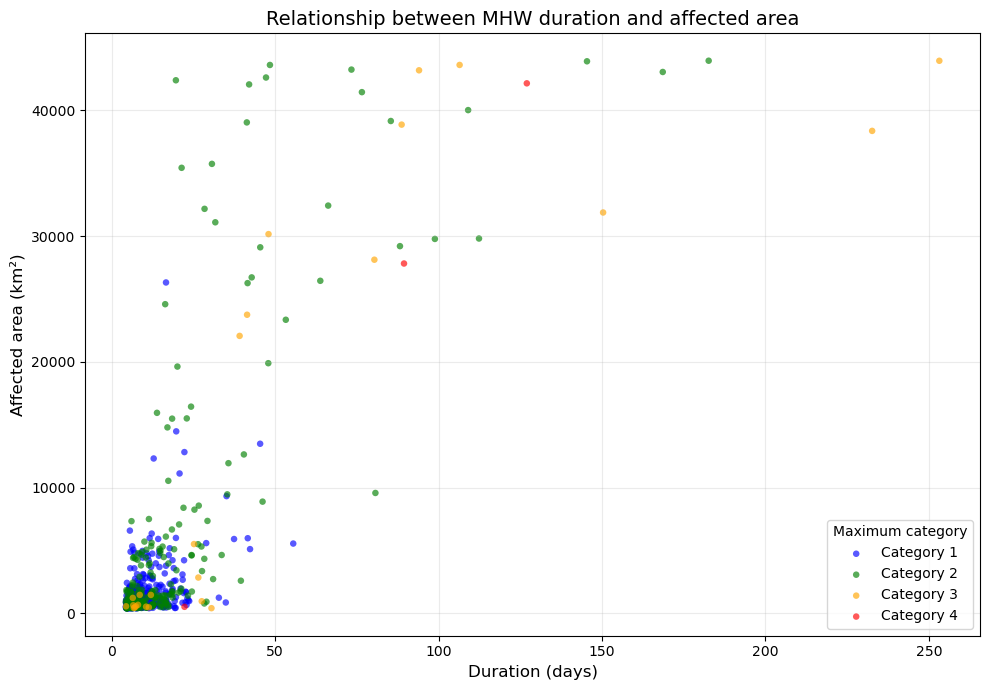

In [5]:

# ============================================================
# INPUT FILE
# ============================================================

input_file = r"D:\XRAST\HMWBP\BPMHW\BP_reg_mhw_sumF2.csv"



# ============================================================
# READ DATA
# ============================================================

df = pd.read_csv(input_file)

df["days"] = pd.to_numeric(df["days"], errors="coerce")
df["area_km2"] = pd.to_numeric(df["area_km2"], errors="coerce")
df["max_cat"] = pd.to_numeric(df["max_cat"], errors="coerce")

df = df.dropna(subset=["days", "area_km2", "max_cat"])


# ============================================================
# COLORS
# ============================================================

category_colors = {
    1: "blue",
    2: "green",
    3: "orange",
    4: "red"
}


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))


# ============================================================
# PLOT
# ============================================================

# Random generator for reproducible jitter
rng = np.random.default_rng(12345)

for cat in sorted(df["max_cat"].unique()):

    subset = df[df["max_cat"] == cat].copy()

    # --------------------------------------------------------
    # Small random displacement to reduce overlap
    # --------------------------------------------------------

    # Horizontal displacement in days
    x_jitter = rng.uniform(-0.7, 0.7, len(subset))

    # Vertical displacement in km2
    # Scaled according to the size of the study area
    y_jitter = rng.uniform(-15, 15, len(subset))

    x = subset["days"].values + x_jitter
    y = subset["area_km2"].values + y_jitter

    ax.scatter(
        x,
        y,
        s=22,                       # slightly larger circles
        marker="o",
        color=category_colors.get(int(cat), "gray"),
        alpha=0.65,
        edgecolor="none",
        label=f"Category {int(cat)}"
    )


# ============================================================
# AXES
# ============================================================

ax.set_xlabel("Duration (days)", fontsize=12)
ax.set_ylabel("Affected area (km²)", fontsize=12)

ax.set_title(
    "Relationship between MHW duration and affected area",
    fontsize=14
)

ax.grid(True, alpha=0.25)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    title="Maximum category",
    loc="best",
    frameon=True
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()
plt.savefig(
    r"D:/XRAST/HMWBP/BPMHW/BPFIGMHW/BP_mhw_duration_area.jpg",
    dpi=300,
    bbox_inches="tight"
)
plt.show()